# 01 — Inventory of the Hanoi PM2.5 stations on OpenAQ

**Goal (report §5, step 1 of §7):** list the Hanoi monitoring stations available on OpenAQ, measure their PM2.5
coverage, and choose the station that supplies the target series.

**How the data is accessed.** The report planned to use the OpenAQ API v3 (`/v3/locations`, `/v3/sensors/{id}/measurements`),
which needs an `X-API-Key`. OpenAQ also publishes *every* measurement in a public AWS bucket
(`s3://openaq-data-archive`, one gzipped CSV per location and per day), which needs no key and has no 60 req/min limit.
It carries the same records, sensor ids, units and timestamps with their UTC offset, so we use it for the bulk
download (`src/openaq_archive.py`). The API client stays available in `openaq_archive.api_locations_near` for a cross-check
when `OPENAQ_API_KEY` is set.

**Finding the location ids.** The archive is indexed by location id. Hanoi ids were found from the OpenAQ Explorer
(`explore.openaq.org/locations/<id>`) and by probing the neighbouring ids in the archive: the Hanoi government network
is the consecutive block `2161290–2161323` (data from Jan 2024), the newer Hanoi Air Quality Monitoring Network block is
`4946811–4946813` (from Jul 2025), and the US Embassy monitor appears as `7441` (AirNow feed, from Nov 2016) and `2539`
(older id, 2016 only).

Raw files are downloaded once with `uv run python src/download_openaq.py` (cached in `data/raw/openaq/`).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from plotting import apply_style, save, SERIES, TEXT_2, MODEL_COLORS, SEQ_CMAP
apply_style()
pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_colwidth", 60)
from openaq_archive import HANOI_LOCATION_IDS, file_inventory
from preprocessing import clean_hourly_pm25, daily_mean

## 1. File-level inventory (from the archive listing only)

In [2]:
files = file_inventory(HANOI_LOCATION_IDS)
meta = pd.read_csv(ROOT / "data/interim/openaq_locations.csv").set_index("location_id")
inv = (files.groupby("location_id")["date"].agg(n_daily_files="size", first_file="min", last_file="max")
       .join(meta[["name", "lat", "lon", "parameters"]]))
inv.sort_values("n_daily_files", ascending=False)

,n_daily_files,first_file,last_file,name,lat,lon,parameters
location_id,,,,,,,
7441,2578,2016-11-09,2025-04-09,Hanoi,21.021939,105.818806,pm25
2161292,880,2024-01-29,2026-11-03,Chi cục Bảo vệ Môi trường,21.015200,105.799900,"co,no2,o3,pm10,pm25,so2"
2161306,673,2024-01-29,2026-11-05,Minh Khai - Bắc Từ Liêm,21.050000,105.740000,"co,no2,o3,pm10,pm25,so2"
4946813,486,2025-07-03,2026-11-05,ĐH Bách Khoa - cổng Parabol đường Giải Phóng,21.005200,105.841800,"co,no2,o3,pm10,pm25,so2"
4946812,484,2025-07-03,2026-11-05,"Công viên hồ điều hòa Nhân Chính, Khuất Duy Tiến",21.003100,105.794700,"co,no2,o3,pm10,pm25,so2"
2161320,471,2024-01-29,2025-06-10,Vân Hà,21.147600,105.915900,"co,no2,pm10,pm25"
2161290,414,2024-01-29,2025-06-10,An Khánh,21.002400,105.718100,"co,no2,pm10,pm25"
2161323,387,2024-01-29,2025-03-17,Xuân Mai,20.899400,105.577300,"co,no2,pm10,pm25"
4946811,352,2025-07-03,2026-07-15,556 Nguyễn Văn Cừ,21.049100,105.883100,"co,no2,o3,pm10,pm25,so2"


## 2. PM2.5 coverage per station

For each station: hourly cleaning (sentinel −999 and negative values removed, duplicates averaged, frozen-sensor runs removed),
reindexing on a regular hourly grid, then:

* **hourly completeness** = present hours / hours between first and last record;
* **winter coverage** = present hours / all hours of Nov–Mar of that winter (full-season denominator);
* **valid days** = local days with ≥ 18 of 24 hours.

In [3]:
raw = pd.read_parquet(ROOT / "data/interim/openaq_pm25_raw.parquet")
hourly, reports = {}, {}
for loc, g in raw.groupby("location_id"):
    s, rep = clean_hourly_pm25(g)
    hourly[loc], reports[loc] = s, rep

def winter_coverage(s):
    local = s.copy(); local.index = local.index.tz_convert("Asia/Bangkok")
    out = {}
    for y in range(2016, 2027):
        idx = pd.date_range(f"{y}-11-01", f"{y+1}-04-01", freq="h", tz="Asia/Bangkok", inclusive="left")
        c = local.reindex(idx).notna().mean()
        if c > 0.02:
            out[f"{y}-{(y+1) % 100:02d}"] = round(c, 2)
    return out

rows = []
for loc, s in hourly.items():
    rep, d = reports[loc], daily_mean(s)
    w = winter_coverage(s)
    present = s.dropna().index.tz_convert("Asia/Bangkok")
    rows.append({
        "location_id": loc, "name": meta.loc[loc, "name"],
        "first": present.min().date() if len(present) else None,
        "last": present.max().date() if len(present) else None,
        "record_interval": rep.get("record_interval"),
        "removed_negative": rep["negative_or_sentinel"], "removed_stuck": rep["stuck_values"],
        "hourly_completeness": round(rep["coverage"], 3), "valid_days": int(d["valid"].sum()),
        "winters_ge_85pct": sum(v >= 0.85 for v in w.values()), "winter_coverage": w,
        "mean_pm25": round(s.mean(), 1),
    })
cov = pd.DataFrame(rows).set_index("location_id").sort_values("valid_days", ascending=False)
cov

,name,first,last,record_interval,removed_negative,removed_stuck,hourly_completeness,valid_days,winters_ge_85pct,winter_coverage,mean_pm25
location_id,,,,,,,,,,,
7441,Hanoi,2016-11-09,2025-04-09,0 days 01:00:00,8360,0,0.692,2080,3,"{'2016-17': 0.91, '2017-18': 0.6, '2018-19': 0.94, '2019...",45.1
2161292,Chi cục Bảo vệ Môi trường,2024-01-29,2026-11-03,0 days 01:00:00,57,0,0.707,646,1,"{'2023-24': 0.35, '2024-25': 0.97, '2025-26': 0.44}",31.8
4946812,"Công viên hồ điều hòa Nhân Chính, Khuất Duy Tiến",2025-07-03,2026-11-05,0 days 00:05:00,0,0,0.959,465,1,"{'2025-26': 0.97, '2026-27': 0.03}",32.4
4946813,ĐH Bách Khoa - cổng Parabol đường Giải Phóng,2025-07-03,2026-11-05,0 days 00:05:00,0,0,0.928,457,1,"{'2025-26': 0.93, '2026-27': 0.03}",39.5
2161320,Vân Hà,2024-01-29,2025-06-10,0 days 01:00:00,0,0,0.880,425,1,"{'2023-24': 0.36, '2024-25': 0.96}",41.0
2161290,An Khánh,2024-01-29,2025-06-10,0 days 01:00:00,0,0,0.788,380,1,"{'2023-24': 0.32, '2024-25': 0.98}",39.4
4946811,556 Nguyễn Văn Cừ,2025-07-03,2026-07-15,0 days 00:05:00,0,0,0.865,318,1,{'2025-26': 0.94},46.3
2161323,Xuân Mai,2024-01-29,2025-03-17,0 days 01:00:00,0,0,0.801,306,1,"{'2023-24': 0.19, '2024-25': 0.88}",41.0
2161312,Sóc Sơn,2024-01-29,2025-03-19,0 days 01:00:00,0,0,0.747,302,1,"{'2023-24': 0.36, '2024-25': 0.9}",29.3


### Selection criteria of the report (§5)

In [4]:
crit = pd.DataFrame({
    "name": cov["name"],
    ">=2 winters with >=85% hours": cov["winters_ge_85pct"] >= 2,
    ">=85% hourly completeness": cov["hourly_completeness"] >= 0.85,
    "identified station": True,   # every OpenAQ location has a name, id and coordinates
    "data until >= 2025": pd.to_datetime(cov["last"]) >= "2025-01-01",
})
crit["criteria_met"] = crit.iloc[:, 1:].sum(axis=1)
crit.sort_values(["criteria_met"], ascending=False).head(12)

,name,>=2 winters with >=85% hours,>=85% hourly completeness,identified station,data until >= 2025,criteria_met
location_id,,,,,,
7441,Hanoi,True,False,True,True,3
4946812,"Công viên hồ điều hòa Nhân Chính, Khuất Duy Tiến",False,True,True,True,3
4946813,ĐH Bách Khoa - cổng Parabol đường Giải Phóng,False,True,True,True,3
4946811,556 Nguyễn Văn Cừ,False,True,True,True,3
2161320,Vân Hà,False,True,True,True,3
2161293,Chúc Sơn,False,True,True,True,3
2161292,Chi cục Bảo vệ Môi trường,False,False,True,True,2
2161290,An Khánh,False,False,True,True,2
2161323,Xuân Mai,False,False,True,True,2


### Monthly PM2.5 coverage of the main candidates

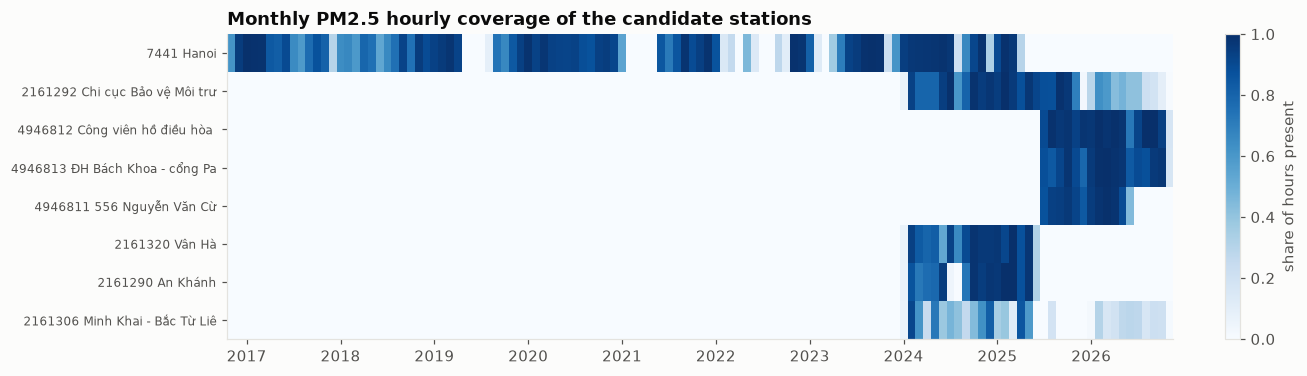

In [5]:
cands = [7441, 2161292, 4946812, 4946813, 4946811, 2161320, 2161290, 2161306]
monthly = {}
for loc in cands:
    s = hourly[loc].copy(); s.index = s.index.tz_convert("Asia/Bangkok").tz_localize(None)
    full = pd.date_range("2016-11-01", "2026-11-30 23:00", freq="h")
    monthly[f"{loc} {meta.loc[loc, 'name'][:22]}"] = s.reindex(full).notna().groupby(full.to_period("M")).mean()
mcov = pd.DataFrame(monthly).T

fig, ax = plt.subplots(figsize=(12, 3.6))
im = ax.imshow(mcov.values, aspect="auto", cmap=SEQ_CMAP, vmin=0, vmax=1, interpolation="nearest")
ax.set_yticks(range(len(mcov)), mcov.index, fontsize=8)
years = [i for i, p in enumerate(mcov.columns) if p.month == 1]
ax.set_xticks(years, [mcov.columns[i].year for i in years])
ax.grid(False)
fig.colorbar(im, ax=ax, label="share of hours present", fraction=0.025)
ax.set_title("Monthly PM2.5 hourly coverage of the candidate stations")
save(fig, "01_station_monthly_coverage", ROOT)

## 3. Which station is behind the Kaggle file?

The Kaggle file has no station identifier (report §4). We compare its hourly PM2.5 with every candidate,
trying both readings of its timestamp (UTC as documented, or local time) and ±1 h offsets.

In [6]:
k = pd.read_csv(ROOT / "data/kaggle-hanoi_air_quality/hanoi_aqi_ml_ready_fixed.csv", parse_dates=["datetime"])
match = []
for tz in ["UTC", "Asia/Bangkok"]:
    ks = k.set_index("datetime")["pm25"]
    ks.index = ks.index.tz_localize(tz).tz_convert("UTC")
    for loc in cands:
        for shift in (-1, 0, 1):
            j = pd.concat([ks, hourly[loc].shift(shift, freq="h")], axis=1, join="inner").dropna()
            if len(j) > 100:
                match.append({"kaggle_tz": tz, "location_id": loc, "shift_h": shift, "n": len(j),
                              "r": j.corr().iloc[0, 1],
                              "share_identical": np.isclose(j.iloc[:, 0], j.iloc[:, 1], atol=0.01).mean()})
match = pd.DataFrame(match).sort_values("share_identical", ascending=False)
match.head(6).round(3)

,kaggle_tz,location_id,shift_h,n,r,share_identical
5,UTC,2161292,1,14251,0.966,0.876
10,UTC,4946813,0,3331,0.871,0.002
4,UTC,2161292,0,14157,0.912,0.002
35,Asia/Bangkok,4946813,1,3316,0.535,0.002
3,UTC,2161292,-1,14117,0.864,0.002
9,UTC,4946813,-1,3329,0.773,0.002


In [7]:
best = match.iloc[0]
ks = k.set_index("datetime")[["pm25", "source"]]; ks.index = ks.index.tz_localize("UTC")
st = hourly[int(best.location_id)].shift(int(best.shift_h), freq="h").rename("station")
j = ks.join(st, how="left")
j["identical"] = np.isclose(j["pm25"], j["station"], atol=0.01)
print(f"Kaggle rows identical to station {int(best.location_id)}: {j.identical.mean():.1%}")
j.groupby("source")["identical"].agg(["mean", "size"]).round(3)

Kaggle rows identical to station 2161292: 86.4%


,mean,size
source,,
5-year,0.000,174
5-year+OpenAQ,0.000,1760
OpenAQ,0.998,12517


**Result.** 86 % of all Kaggle hours, and 99.8 % of the rows whose `source` is “OpenAQ”, are *identical* to OpenAQ location **2161292 “Chi cục Bảo vệ Môi trường”**
(Hanoi Environmental Protection Sub-Department, 21.0152 N 105.7999 E) once the Kaggle timestamp is read as **UTC at the
end of the hour** (the raw OpenAQ convention). The 1,934 rows labelled “5-year” / “5-year+OpenAQ” (Jul–Sep 2025) match no station and come from another source. This settles the
time-zone question of report §4: the Kaggle timestamps are in UTC, while its weather columns turn out to be in local time
(notebook 02), so the file joins weather and PM2.5 7 hours apart.

## 4. Can two stations be combined? US Embassy (7441) vs Chi cục BVMT (2161292)

The report allows combining two stations *after checking that their levels agree*. These two stations are about 2 km
apart and overlap from Jan 2024 to Apr 2025.

335 common valid days (2024-01-30 to 2025-04-09)
correlation r = 0.747
mean difference (2161292 - 7441) = -11.7 µg/m³, MAE = 13.1, ratio of means = 0.75


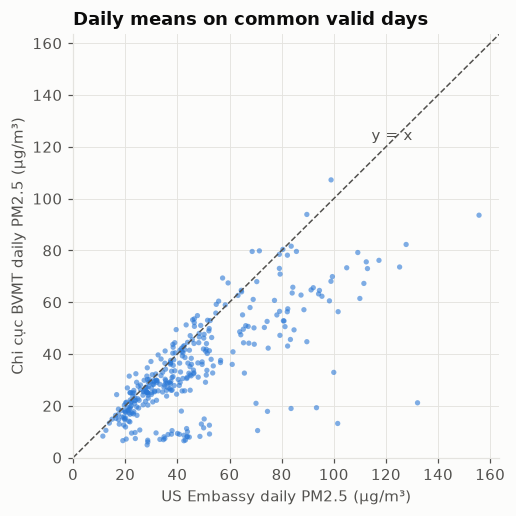

In [8]:
d1 = daily_mean(hourly[7441])["mean"].rename("US Embassy (7441)")
d2 = daily_mean(hourly[2161292])["mean"].rename("Chi cục BVMT (2161292)")
both = pd.concat([d1, d2], axis=1, join="inner").dropna()
diff = both.iloc[:, 1] - both.iloc[:, 0]
print(f"{len(both)} common valid days ({both.index.min().date()} to {both.index.max().date()})")
print(f"correlation r = {both.corr().iloc[0, 1]:.3f}")
print(f"mean difference (2161292 - 7441) = {diff.mean():.1f} µg/m³, MAE = {diff.abs().mean():.1f}, ratio of means = {both.iloc[:,1].mean()/both.iloc[:,0].mean():.2f}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(both.iloc[:, 0], both.iloc[:, 1], s=12, alpha=0.6, color=SERIES[0], edgecolor="none")
lim = [0, both.max().max() * 1.05]
ax.plot(lim, lim, color=TEXT_2, lw=1, ls="--"); ax.text(lim[1] * 0.7, lim[1] * 0.75, "y = x", color=TEXT_2)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("US Embassy daily PM2.5 (µg/m³)"); ax.set_ylabel("Chi cục BVMT daily PM2.5 (µg/m³)")
ax.set_title("Daily means on common valid days")
save(fig, "01_station_agreement", ROOT)

The two levels **do not agree**: the government station reads about 25 % lower on average (≈ −12 µg/m³), with r ≈ 0.75.
Joining them would put a level shift inside the target series, so we do **not** combine them.

## 5. Decision

| | US Embassy `7441` | Chi cục BVMT `2161292` (Kaggle source) | Nhân Chính `4946812` |
|---|---|---|---|
| Period | Nov 2016 – Apr 2025 | Jan 2024 – Nov 2026 | Jul 2025 – Nov 2026 |
| Winters with ≥ 85 % of hours | **3** (2016-17, 2018-19, 2019-20), 2024-25 at 83 % | 1 (2024-25) | 1 (2025-26) |
| Hourly completeness | 69 % | 71 % | 96 % |
| Valid days (≥ 18 h) | **2,080** | 646 | 465 |
| Identified | yes (US Embassy, AirNow, reference BAM) | yes | yes |
| Data until ≥ 2025 | yes (stops 9 Apr 2025) | yes | yes |

No station meets all four thresholds; the overall-completeness criterion fails everywhere except at the 2025 network, which has
only one winter. We choose the **US Embassy monitor (location 7441, sensor 21632)** as the target station:
it gives several well-covered winters and 3.5× more valid days than the Kaggle series. The overall 69 % comes mainly from the
2020–2023 outages, which are handled explicitly by the valid-day rule. Its limit is that it stopped reporting in April 2025, so it
cannot feed an operational forecast today.

As a secondary dataset, built with exactly the same pipeline, we keep **2161292** (the identified Kaggle station, still active).
It is used to check that the model ranking holds on a different, current station.

In [9]:
cov.to_csv(ROOT / "data/interim/station_inventory.csv")
crit.to_csv(ROOT / "data/interim/station_criteria.csv")